# QIUP 3.4 — MNIST object on the SLM across four arrangements

This notebook places one MNIST digit as intensity `T` on the SLM and builds the camera output for all four arrangements:

| Arrangement | Architecture | Imaging | Object |
|---|---|---|---|
| A | two-crystal (NL1/NL2) | far field | T (transmissive) |
| B | single-crystal double-pass (NL) | near field | R (reflective) |
| C | single-crystal double-pass (NL) | far field | R (reflective) |
| D | two-crystal (NL1/NL2) | near field | T (transmissive) |

- **Ideal**: all noise and disturbance sources off; the SLM image is visible on the camera.
- **Noisy**: mild noise so the object remains recognizable.

To change the sample, edit only `MNIST_INDEX` in the parameters cell and re-run from that cell downward. `MNIST_INDEX` is the train-list index, not the digit itself; the true label is printed in the next cell.


## 1. Environment and imports


In [1]:
import copy
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "setup_params.py").is_file():
    raise RuntimeError(f"Run this notebook from the 3.4 package folder; cwd={ROOT}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("PYTHONDONTWRITEBYTECODE", "1")

import generate_mnist5_four_arrangement_images as gen
from latents import LatentState
from setup_params import resolve_setup_selection
from simulate import simulate_forward

%matplotlib inline
print("package root:", ROOT)

package root: h:\Quantum AI\Noise cancling and Enhancment Image\code\DT version 3.3.3 plus\Synthetic_3.3.3_22Sep\3.4 25sep


## 2. Run parameters (edit here)


In [2]:
MNIST_INDEX = 5
SIZE = 64
SEED = 15000

OUT = ROOT / "outputs" / f"mnist_index{MNIST_INDEX}_four_arrangements"
OUT.mkdir(parents=True, exist_ok=True)
print("output folder:", OUT)

output folder: h:\Quantum AI\Noise cancling and Enhancment Image\code\DT version 3.3.3 plus\Synthetic_3.3.3_22Sep\3.4 25sep\outputs\mnist_index5_four_arrangements


## 3. Load MNIST sample and build the SLM object

`T = MNIST / 255` with zero phase. If local MNIST files are missing, they are downloaded once into `data/MNIST/raw`.


MNIST train[5]  label=2  source=mnist_idx_files  SLM grid=(64, 64)


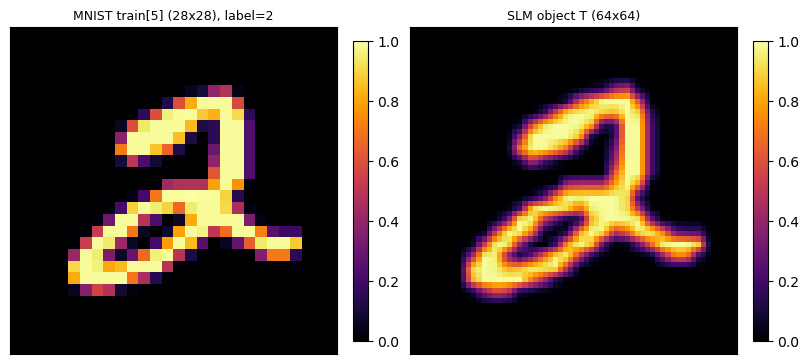

In [3]:
ref, raw, digit_label, source = gen.mnist_reference(MNIST_INDEX, SIZE)
slm = np.asarray(ref["T"], dtype=np.float64)
print(f"MNIST train[{MNIST_INDEX}]  label={digit_label}  source={source}  SLM grid={slm.shape}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for ax, data, title in (
    (axes[0], raw / 255.0, f"MNIST train[{MNIST_INDEX}] (28x28), label={digit_label}"),
    (axes[1], slm, f"SLM object T ({SIZE}x{SIZE})"),
):
    im = ax.imshow(data, cmap="inferno", vmin=0.0, vmax=1.0)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()

gen._save_png(OUT / f"mnist_index{MNIST_INDEX}_native.png", raw / 255.0, f"MNIST train[{MNIST_INDEX}] label={digit_label}", 0.0, 1.0)
gen._save_png(OUT / f"mnist_index{MNIST_INDEX}_slm_object.png", slm, f"SLM object T | index {MNIST_INDEX}, label {digit_label}", 0.0, 1.0)
gen._save_array(OUT / f"mnist_index{MNIST_INDEX}_slm_object.npy", slm)

## 4. Noise parameters

Default values are copied from `generate_mnist5_four_arrangement_images.py`. You can override any value here, for example `NOISY_LATENTS["s_det"] = 0.2` or `NOISY_LATENTS["em_gain"] = 50`.

- `*_SETUP`: physical layout parameters (blur, correlation PSF, camera, pump geometry).
- `*_LATENTS`: `s_*` instabilities, gain, `nbar`, and exposure.


In [4]:
IDEAL_SETUP = copy.deepcopy(gen.IDEAL_SETUP)
IDEAL_LATENTS = copy.deepcopy(gen.IDEAL_LATENTS)
NOISY_SETUP = copy.deepcopy(gen.NOISY_SETUP)
NOISY_LATENTS = copy.deepcopy(gen.NOISY_LATENTS)

# Example edits:
# NOISY_LATENTS["s_det"] = 0.20
# NOISY_LATENTS["em_gain"] = 50.0
# NOISY_SETUP["prnu_sigma"] = 0.02

keys = sorted(set(IDEAL_SETUP) | set(NOISY_SETUP) | set(IDEAL_LATENTS) | set(NOISY_LATENTS))
print(f"{'parameter':32s} {'ideal':>14s} {'noisy':>14s}")
print("-" * 62)
for key in keys:
    ideal_value = IDEAL_SETUP.get(key, IDEAL_LATENTS.get(key, "-"))
    noisy_value = NOISY_SETUP.get(key, NOISY_LATENTS.get(key, "-"))
    print(f"{key:32s} {str(ideal_value):>14s} {str(noisy_value):>14s}")
print("-" * 62)
print(f"{'detector_noise':32s} {'False':>14s} {'True':>14s}")

parameter                                 ideal          noisy
--------------------------------------------------------------
accidental_e_at_s1                          0.0          0.004
blur_model                          single_blur    single_blur
cic0                                        0.0          0.002
couple_align_to_wavefront                 False          False
dT_NL1_C                                    0.0            0.0
dT_NL2_C                                    0.0            0.0
dark0                                       0.0         0.0008
delta_M_rel                                 0.0            0.0
delta_phi_align_span_rad                    0.0           0.08
delta_phi_rms                               0.0           0.04
delta_z_um                                  0.0            0.0
em_gain                                     1.0           20.0
enable_etalon_fringes                     False          False
enable_lens_rings                         False        

## 5. One-arrangement runner


In [6]:
PROFILE_INFO = {selector: (slug, label) for selector, slug, label in gen.PROFILES}
images = {}
summary = {
    "mnist_index": MNIST_INDEX,
    "mnist_label": digit_label,
    "object_source": source,
    "object_encoding": "intensity T = MNIST/255, phase = 0",
    "grid": SIZE,
    "seed": SEED,
    "ideal_setup": IDEAL_SETUP,
    "ideal_latents": IDEAL_LATENTS,
    "noisy_setup": NOISY_SETUP,
    "noisy_latents": NOISY_LATENTS,
    "profiles": {},
}


def run_profile(selector: str) -> None:
    slug, label = PROFILE_INFO[selector]
    base = resolve_setup_selection(selector)
    setup_ideal = base.overridden(**gen._allowed_overrides(base, IDEAL_SETUP))
    setup_noisy = base.overridden(**gen._allowed_overrides(base, NOISY_SETUP))
    ideal = simulate_forward(ref, LatentState(setup=setup_ideal, **IDEAL_LATENTS), seed=SEED, detector_noise=False)
    noisy = simulate_forward(ref, LatentState(setup=setup_noisy, **NOISY_LATENTS), seed=SEED, detector_noise=True)
    ideal_img = np.asarray(ideal.ideal_signal_image, dtype=np.float64)
    noisy_img = np.asarray(noisy.detector_signal_image, dtype=np.float64)
    images[selector] = {"ideal": ideal_img, "noisy": noisy_img}

    fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
    for ax, data, title, vmin, vmax in (
        (axes[0], slm, "SLM object T", 0.0, 1.0),
        (axes[1], ideal_img, "ideal (all noise off)", None, None),
        (axes[2], noisy_img, "noisy (detector ADU)", None, None),
    ):
        im = ax.imshow(data, cmap="inferno", vmin=vmin, vmax=vmax)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{selector}: {label}", fontsize=11)
    plt.show()

    prefix = f"{selector}_{slug}"
    gen._save_png(OUT / f"{prefix}_ideal_signal.png", ideal_img, f"{selector} ideal | {label}")
    gen._save_png(OUT / f"{prefix}_noisy_detector.png", noisy_img, f"{selector} noisy | {label}")
    gen._save_array(OUT / f"{prefix}_ideal_signal.npy", ideal_img)
    gen._save_array(OUT / f"{prefix}_noisy_detector.npy", noisy_img)
    summary["profiles"][selector] = {
        "slug": slug,
        "label": label,
        "object_type": setup_ideal.object_type,
        "object_plane": setup_ideal.object_plane,
        "ideal_min": float(ideal_img.min()),
        "ideal_max": float(ideal_img.max()),
        "noisy_min": float(noisy_img.min()),
        "noisy_max": float(noisy_img.max()),
        "ideal_sha256": ideal.meta.get("ideal_signal_image_sha256"),
        "noisy_sha256": noisy.meta.get("detector_signal_image_sha256"),
    }
    print(f"{selector}: ideal max={ideal_img.max():.4g}   noisy max={noisy_img.max():.4g}")

## 6. Arrangement A — two-crystal, far field, object T


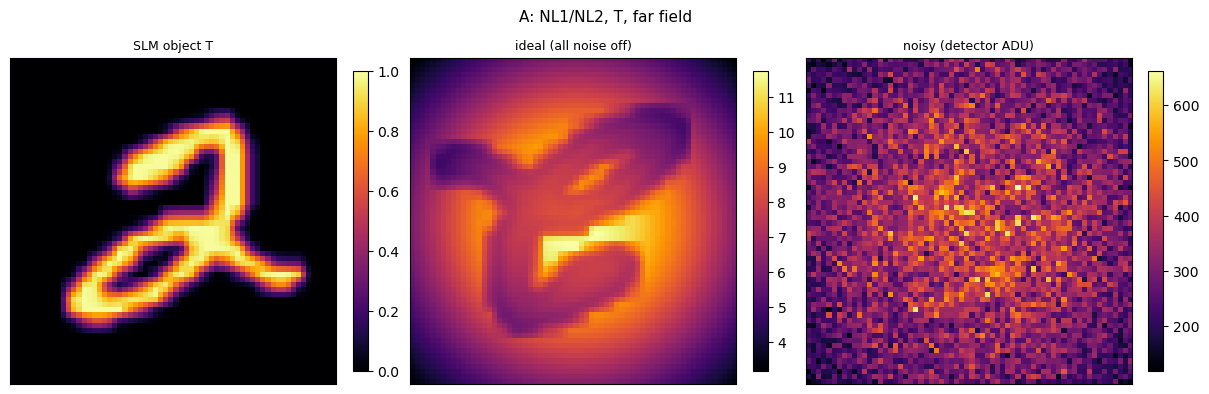

A: ideal max=11.75   noisy max=663


In [6]:
run_profile("A")

## 7. Arrangement B — single-crystal double-pass, near field, object R


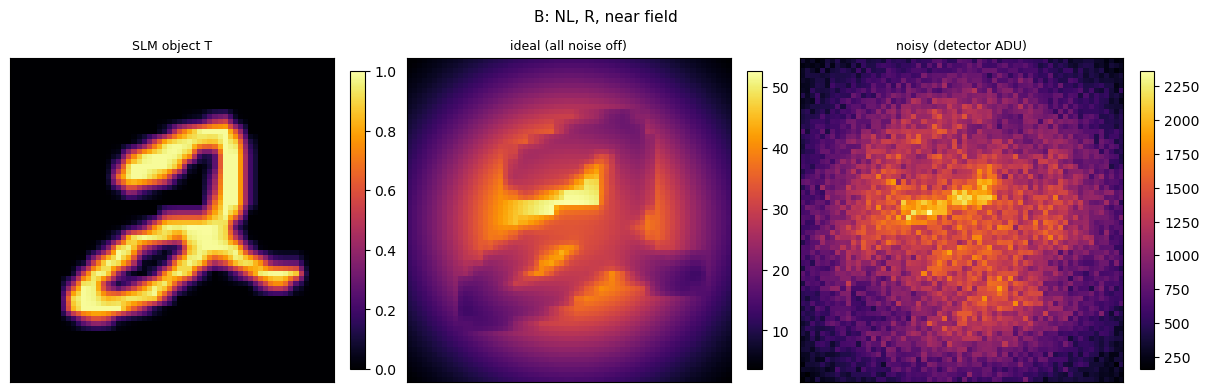

B: ideal max=52.68   noisy max=2363


In [7]:
run_profile("B")

## 8. Arrangement C — single-crystal double-pass, far field, object R


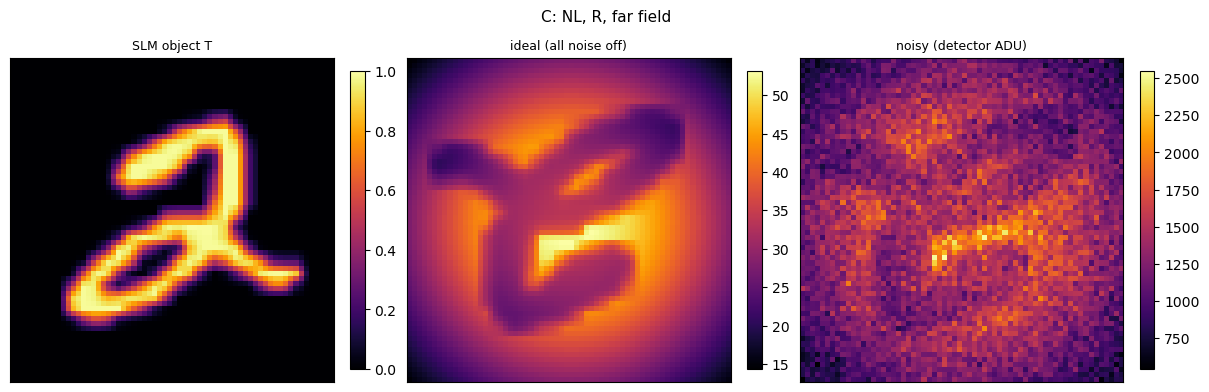

C: ideal max=53.12   noisy max=2549


In [8]:
run_profile("C")

## 9. Arrangement D — two-crystal, near field, object T


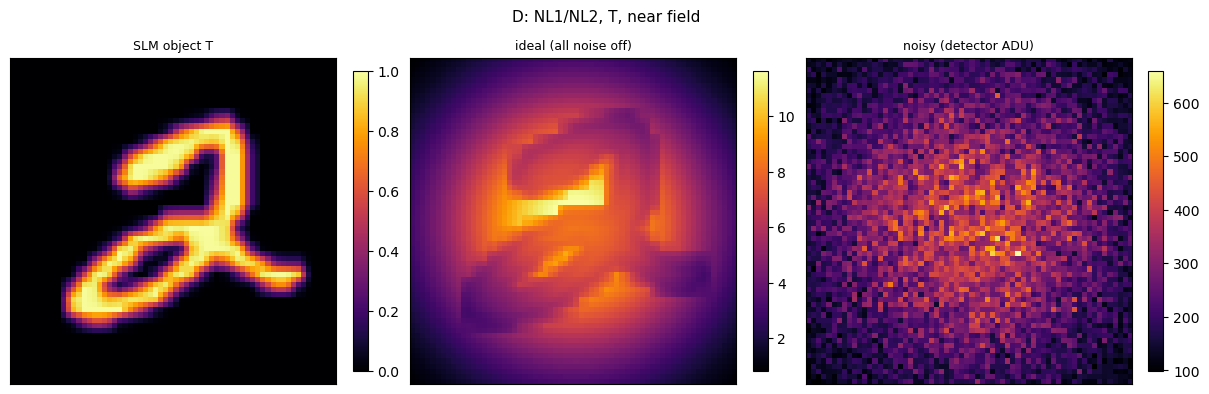

D: ideal max=11.65   noisy max=660


In [9]:
run_profile("D")

## 10. Four-arrangement comparison figure and summary save


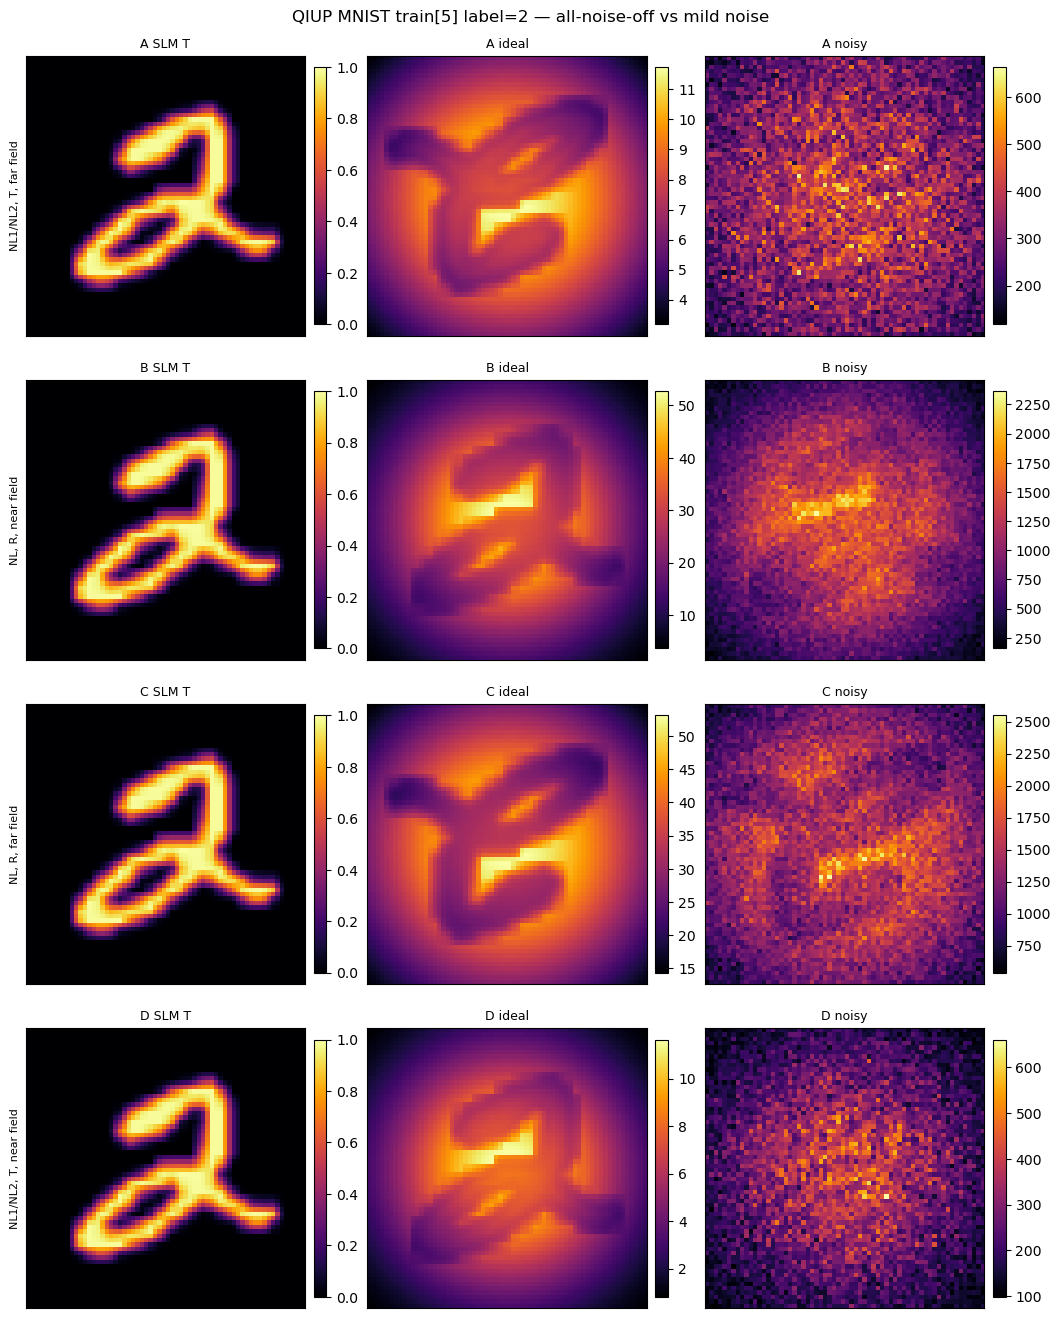

saved: H:\Quantum AI\Noise cancling and Enhancment Image\code\DT version 3.3.3 plus\Synthetic_3.3.3_22Sep\3.4 25sep\outputs\mnist_index5_four_arrangements


In [10]:
missing = [s for s, _, _ in gen.PROFILES if s not in images]
if missing:
    raise RuntimeError(f"run the profile cells first: {missing}")

fig, axes = plt.subplots(4, 3, figsize=(10.5, 13.2), constrained_layout=True)
for row, (selector, slug, label) in enumerate(gen.PROFILES):
    for col, (data, title, vmin, vmax) in enumerate((
        (slm, f"{selector} SLM T", 0.0, 1.0),
        (images[selector]["ideal"], f"{selector} ideal", None, None),
        (images[selector]["noisy"], f"{selector} noisy", None, None),
    )):
        ax = axes[row, col]
        im = ax.imshow(data, cmap="inferno", vmin=vmin, vmax=vmax)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    axes[row, 0].set_ylabel(label, fontsize=8)
fig.suptitle(f"QIUP MNIST train[{MNIST_INDEX}] label={digit_label} — all-noise-off vs mild noise", fontsize=12)
fig.savefig(OUT / "comparison_A_B_C_D_ideal_vs_noisy.png", dpi=170)
plt.show()

(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("saved:", OUT)